# 04 Knowledge graph

**Goal:** turn the event timeline and the troubleshooting guide into one **knowledge graph**: dots (**nodes**) joined by labelled lines (**edges**).

It has two layers:
- **Knowledge layer** (from the guide): defects, causes, alarm codes, fixes, and the rules that link them. *"Alarm 2105 indicates dirty glass"*, *"dirty glass causes incomplete cut"*.
- **Event layer** (from the timeline): what actually happened. *"Alarm 2105 happened 3 h before job 340"*, *"job 340 has defect incomplete cut"*.

The two layers meet at the alarm codes, causes and defects. That's what lets the system walk from a bad job to a likely cause, with evidence.

This is the **event-centric knowledge graph** from your supervisor's direction, for now with logs and tables only (no photos or video).

We use **networkx** (included in Anaconda, so nothing to install). The graph is also saved as `nodes.csv` and `edges.csv`, which can be loaded into Neo4j later.

## 0. Setup

In [1]:
from pathlib import Path
import pickle
import pandas as pd
import networkx as nx

DATA = Path("..") / "datasets"
OUT = Path("..") / "data" / "processed"

tl = pd.read_csv(OUT / "event_timeline.csv")
tl["time"] = pd.to_datetime(tl["time"], format="ISO8601")
G = nx.DiGraph()
print(len(tl), "timeline events")

1204 timeline events


## 1. Knowledge layer: written from the troubleshooting guide
These small tables are the guide (sections 2 to 4) typed out as data. Each row will become nodes and edges.

**Causes:** the guide lists the possible causes for each defect, most likely first (`rank`).
Some causes in the guide can't be checked with our data (for example focus position). They stay in the graph anyway, because the guide lists them, but the system will find no evidence for them.

In [2]:
# cause id -> description, the fix, and a rule we can check in the data (guide sections 2, 4 and 5)
CAUSES = {
    "glass_dirty":              {"text": "Protective glass contaminated or damaged (beam power reduced)",
                                 "fix": "Clean or replace protective glass", "rule": "check every shift (8 h)"},
    "nozzle_worn":              {"text": "Nozzle worn or damaged (orifice no longer round)",
                                 "fix": "Replace nozzle", "rule": "replace every 40-60 operating hours"},
    "gas_supply_low":           {"text": "Cutting gas pressure too low or supply unstable",
                                 "fix": "Check tank, regulator and lines", "rule": "watch for messages 1201/1202"},
    "feed_too_high":            {"text": "Feed rate too high for the thickness",
                                 "fix": "Return to cutting-table feed rate", "rule": "max +10 % above cutting table; _FAST programs not released"},
    "bevel_out_of_calibration": {"text": "Bevel axis / height sensor out of calibration after a collision",
                                 "fix": "Calibrate height sensor and bevel axis", "rule": "calibrate after any collision"},
    "focus_wrong":              {"text": "Focus position wrong", "fix": "Run focus test", "rule": "not logged"},
    "feed_too_low":             {"text": "Feed rate too low (overburning, mild steel)", "fix": "Increase feed rate", "rule": "compare with cutting table"},
    "material_surface":         {"text": "Material surface rusty or oily", "fix": "Use clean sheet", "rule": "not logged"},
}

# (defect, cause, rank, only for gas)  - guide section 2, most likely first
CAUSES_DEFECT = [
    ("dross", "gas_supply_low", 1, "N2"), ("dross", "nozzle_worn", 2, "N2"), ("dross", "focus_wrong", 3, "N2"), ("dross", "feed_too_high", 4, "N2"),
    ("dross", "feed_too_low", 1, "O2"), ("dross", "material_surface", 2, "O2"),
    ("rough_cut", "feed_too_high", 1, None), ("rough_cut", "nozzle_worn", 2, None), ("rough_cut", "glass_dirty", 3, None),
    ("incomplete_cut", "glass_dirty", 1, None), ("incomplete_cut", "feed_too_high", 2, None), ("incomplete_cut", "focus_wrong", 3, None),
    ("bevel_deviation", "bevel_out_of_calibration", 1, None),
    ("burnt_edge", "glass_dirty", 1, None), ("burnt_edge", "feed_too_low", 2, None),
]

# alarm code -> the cause it points to (guide section 3)
INDICATES = {"2105": "glass_dirty", "4001": "glass_dirty", "1201": "gas_supply_low", "1202": "gas_supply_low",
             "3301": "bevel_out_of_calibration", "3302": "bevel_out_of_calibration"}
ALARM_TEXT = {"1201": "Cutting gas pressure below setpoint", "1202": "Cutting gas pressure fluctuation",
              "2105": "Protective glass contamination", "3301": "Collision detected - cutting head",
              "3302": "Height sensor calibration required", "4001": "Laser power reduced", "6002": "Sheet tip-up detected"}

In [3]:
for cid, c in CAUSES.items():
    G.add_node(f"cause:{cid}", kind="Cause", name=cid, **c)
    G.add_node(f"fix:{cid}", kind="Fix", name=c["fix"])
    G.add_edge(f"cause:{cid}", f"fix:{cid}", type="FIXED_BY")

for defect, cid, rank, gas in CAUSES_DEFECT:
    G.add_node(f"defect:{defect}", kind="Defect", name=defect)
    G.add_edge(f"cause:{cid}", f"defect:{defect}", type="CAUSES", rank=rank, gas=gas or "any")

for code_, text in ALARM_TEXT.items():
    G.add_node(f"code:{code_}", kind="AlarmCode", name=code_, text=text)
for code_, cid in INDICATES.items():
    G.add_edge(f"code:{code_}", f"cause:{cid}", type="INDICATES")

print("knowledge layer:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

knowledge layer: 28 nodes, 29 edges


## 2. Event layer: jobs
Each job becomes a node that carries its settings. We re-read the job log for the full settings (same cleaning as notebooks 01 and 03), and add the two columns from the EDA that the guide's rules need:
`feed_vs_table` (feed ÷ cutting-table feed) and `is_fast`.

Jobs are linked in time order with `NEXT`, and to their defect with `HAS_DEFECT` (from the inspection).

In [4]:
jobs = pd.read_csv(DATA / "machine" / "job_log.csv", sep=";", decimal=",").drop_duplicates()
jobs["StartTime"] = pd.to_datetime(jobs["StartTime"], format="%d.%m.%Y %H:%M:%S")
jobs["EndTime"] = pd.to_datetime(jobs["EndTime"], format="%d.%m.%Y %H:%M:%S")
jobs = jobs.sort_values("StartTime").reset_index(drop=True)
jobs["NozzleOperatingHours"] = jobs["NozzleOperatingHours"].ffill()     # same decision as notebook 03

table = pd.read_csv(DATA / "documents" / "cutting_table.csv").rename(columns={
    "material": "Material", "gas": "CuttingGas", "thickness_mm": "Thickness_mm", "feed_rate_mm_min": "table_feed"})
jobs = jobs.merge(table[["Material", "CuttingGas", "Thickness_mm", "table_feed"]], on=["Material", "CuttingGas", "Thickness_mm"], how="left")
jobs["feed_vs_table"] = (jobs["FeedRate_mm_min"] / jobs["table_feed"]).round(2)
jobs["is_fast"] = jobs["ProgramName"].str.contains("_FAST")

insp = tl[tl["event_type"] == "inspection"][["job_id", "detail"]].copy()
insp["defect"] = insp["detail"].str.split(" | ", regex=False).str[1]
jobs = jobs.merge(insp[["job_id", "defect"]], left_on="JobID", right_on="job_id", how="left").drop(columns="job_id")

for _, j in jobs.iterrows():
    G.add_node(f"job:{j['JobID']}", kind="Job", name=j["JobID"], start=j["StartTime"], end=j["EndTime"],
               program=j["ProgramName"], material=j["Material"], thickness=float(j["Thickness_mm"]), gas=j["CuttingGas"],
               feed=float(j["FeedRate_mm_min"]), feed_vs_table=float(j["feed_vs_table"]), is_fast=bool(j["is_fast"]),
               bevel_angle=float(j["BevelAngle_deg"]), nozzle_hours=float(j["NozzleOperatingHours"]),
               gas_pressure_set=float(j["GasPressureSet_bar"]), shift="late" if j["StartTime"].hour >= 14 else "early")
    if pd.notna(j["defect"]) and j["defect"] != "unknown":
        G.add_node(f"defect:{j['defect']}", kind="Defect", name=j["defect"])
        G.add_edge(f"job:{j['JobID']}", f"defect:{j['defect']}", type="HAS_DEFECT")

ids = jobs["JobID"].tolist()
for a, b in zip(ids[:-1], ids[1:]):
    G.add_edge(f"job:{a}", f"job:{b}", type="NEXT")
print(len(jobs), "job nodes")

527 job nodes


## 3. Event layer: alarms
Each WARNING/ERROR alarm becomes a node, linked to its code (`INSTANCE_OF`) and to the job it happened during (`DURING`, from notebook 01).

Then the important part. For each job and each alarm code, we link the job to the **most recent** alarm of that code before the job ended (`LAST_ALARM`), within 7 days.
The edge stores how many hours before the job it was, and how many of that code happened in the 24 h before.
This lets the system ask "what alarms came before this job?" with one step through the graph.

In [5]:
alarms = tl[tl["event_type"] == "alarm"].reset_index(drop=True)
alarms["code"] = alarms["detail"].str.split(" ").str[0]
alarms["node"] = "alarm:" + alarms.index.astype(str)

for _, a in alarms.iterrows():
    G.add_node(a["node"], kind="AlarmEvent", name=a["code"], time=a["time"], text=a["detail"])
    G.add_node(f"code:{a['code']}", kind="AlarmCode", name=a["code"])
    G.add_edge(a["node"], f"code:{a['code']}", type="INSTANCE_OF")
    if pd.notna(a["job_id"]):
        G.add_edge(a["node"], f"job:{a['job_id']}", type="DURING")

n_last = 0
for _, j in jobs.iterrows():
    before = alarms[(alarms["time"] <= j["EndTime"]) & (alarms["time"] >= j["StartTime"] - pd.Timedelta(days=7))]
    for code_, grp in before.groupby("code"):
        last = grp.iloc[-1]
        n24 = (grp["time"] >= j["StartTime"] - pd.Timedelta(hours=24)).sum()
        hours = round((j["StartTime"] - last["time"]).total_seconds() / 3600, 1)    # negative = during the job
        G.add_edge(f"job:{j['JobID']}", last["node"], type="LAST_ALARM", code=code_, hours_before=hours, count_24h=int(n24))
        n_last += 1
print(len(alarms), "alarm nodes,", n_last, "LAST_ALARM edges")

217 alarm nodes, 1665 LAST_ALARM edges


## 4. Event layer: maintenance
Each maintenance entry becomes a node. Entries that **repair** something get a `RESETS` edge to the cause they fix.
The operators wrote free text, so we decide this from keywords (a decision to write in the report):

| keywords | resets |
|---|---|
| glass + clean / wiped / replaced (not "will clean tomorrow") | `glass_dirty` |
| nozzle + changed / replaced / new / fitted (not "no change") | `nozzle_worn` |
| regulator | `gas_supply_low` |
| recalibrat | `bevel_out_of_calibration` |

Then each job is linked to the **last repair before it** for each cause (`AFTER_REPAIR`), with the hours since. That's how "the glass hadn't been cleaned for 30 hours" becomes one edge.

In [6]:
maint = tl[tl["event_type"].str.startswith("maintenance")].reset_index(drop=True)
maint["node"] = "maint:" + maint.index.astype(str)

def resets(text):
    t = text.lower()
    if "glass" in t and any(w in t for w in ["clean", "wiped", "replaced"]) and "tomorrow" not in t:
        return "glass_dirty"
    if "nozzle" in t and any(w in t for w in ["changed", "replaced", "new nozzle", "fitted"]) and "no change" not in t:
        return "nozzle_worn"
    if "regulator" in t:
        return "gas_supply_low"
    if "recalibrat" in t:
        return "bevel_out_of_calibration"
    return None

maint["resets"] = maint["detail"].apply(resets)
for _, m in maint.iterrows():
    G.add_node(m["node"], kind="Maintenance", name=m["event_type"], time=m["time"], text=m["detail"])
    if pd.notna(m["resets"]):
        G.add_edge(m["node"], f"cause:{m['resets']}", type="RESETS")

repairs = maint.dropna(subset=["resets"])
n_rep = 0
for _, j in jobs.iterrows():
    for cid, grp in repairs[repairs["time"] <= j["StartTime"]].groupby("resets"):
        last = grp.iloc[-1]
        hours = round((j["StartTime"] - last["time"]).total_seconds() / 3600, 1)
        G.add_edge(f"job:{j['JobID']}", last["node"], type="AFTER_REPAIR", cause=cid, hours_since=hours)
        n_rep += 1
print(len(maint), "maintenance nodes,", len(repairs), "are repairs,", n_rep, "AFTER_REPAIR edges")
maint[["time", "detail", "resets"]]

44 maintenance nodes, 35 are repairs, 1306 AFTER_REPAIR edges


,time,detail,resets
0,2026-09-01 06:04:00,"glass ok, wiped",glass_dirty
1,2026-09-01 06:10:00,"new nozzle fitted, start of month",nozzle_worn
2,2026-09-02 06:18:00,"glass ok, wiped",glass_dirty
3,2026-09-03 14:05:00,"protective glass checked, cleaned",glass_dirty
4,2026-09-05 14:19:00,"glass ok, wiped",glass_dirty
5,2026-09-07 06:00:00,"protective glass checked, cleaned (time estima...",glass_dirty
6,2026-09-07 14:00:00,"glass ok, wiped (time estimated)",glass_dirty
7,2026-09-08 06:00:00,"nozzle changed, routine (time estimated)",nozzle_worn
8,2026-09-10 06:06:00,"checked prot. glass - slight spatter, cleaned",glass_dirty
9,2026-09-11 06:11:00,"checked prot. glass - slight spatter, cleaned",glass_dirty


## 5. Look at the graph
Count the nodes and edges of each kind, then look at the neighbourhood of one bad job.

In [7]:
print(pd.Series([d["kind"] for _, d in G.nodes(data=True)]).value_counts().to_string())
print()
print(pd.Series([d["type"] for _, _, d in G.edges(data=True)]).value_counts().to_string())

Job            527
AlarmEvent     217
Maintenance     44
Cause            8
Fix              8
AlarmCode        7
Defect           6

LAST_ALARM      1665
AFTER_REPAIR    1306
NEXT             526
HAS_DEFECT       402
INSTANCE_OF      217
DURING           217
RESETS            35
CAUSES            15
FIXED_BY           8
INDICATES          6


In [8]:
JOB = "job:JOB-00391"      # change to any job id
print(JOB, {k: v for k, v in G.nodes[JOB].items() if k in ["program", "gas", "nozzle_hours", "feed_vs_table", "is_fast"]})
for _, target, e in G.out_edges(JOB, data=True):
    if e["type"] != "NEXT":
        print(f"  -{e['type']}-> {target}: {G.nodes[target].get('text', G.nodes[target]['name'])}",
              {k: v for k, v in e.items() if k != "type"})

job:JOB-00391 {'program': 'S235JR_12mm_BEV', 'gas': 'O2', 'feed_vs_table': 1.01, 'is_fast': False, 'nozzle_hours': 14.2}
  -HAS_DEFECT-> defect:incomplete_cut: incomplete_cut {}
  -LAST_ALARM-> alarm:97: 1201 WARNING | Cutting gas pressure below setpoint (N2, set 14.2 bar, actual 9.4 bar) {'code': '1201', 'hours_before': 159.8, 'count_24h': 0}
  -LAST_ALARM-> alarm:145: 2105 WARNING | Protective glass contamination - check and clean {'code': '2105', 'hours_before': 10.5, 'count_24h': 10}
  -LAST_ALARM-> alarm:146: 4001 WARNING | Laser power reduced - beam path monitoring {'code': '4001', 'hours_before': -0.1, 'count_24h': 4}
  -LAST_ALARM-> alarm:108: 6002 WARNING | Sheet tip-up detected - check part {'code': '6002', 'hours_before': 92.9, 'count_24h': 0}
  -AFTER_REPAIR-> maint:27: facilities replaced N2 pressure regulator at tank, pressure ok again {'cause': 'gas_supply_low', 'hours_since': 160.1}
  -AFTER_REPAIR-> maint:29: glass ok, wiped {'cause': 'glass_dirty', 'hours_since': 136.

### Figure: one bad job and what it connects to
Blue = job, red = defect, orange = alarms, green = maintenance, purple = causes from the guide.
Follow the arrows: the job's alarms point to causes, and the same causes point to the job's defect. That shared cause is the explanation.

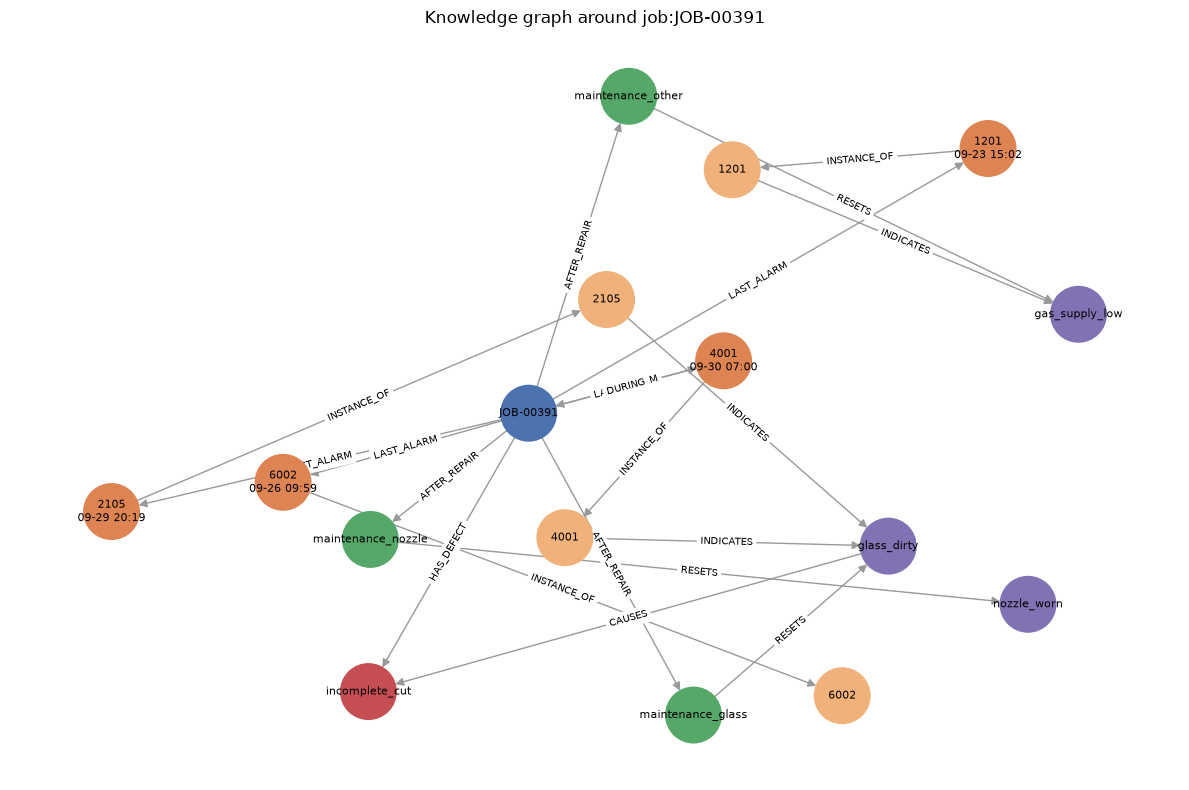

In [9]:
import matplotlib.pyplot as plt

def neighbourhood(job):
    nodes = {job}
    for _, t, e in G.out_edges(job, data=True):
        if e["type"] in ("HAS_DEFECT", "LAST_ALARM", "AFTER_REPAIR"):
            nodes.add(t)
            for _, t2, e2 in G.out_edges(t, data=True):
                if e2["type"] in ("INSTANCE_OF", "RESETS"):
                    nodes.add(t2)
    for n in list(nodes):
        if n.startswith("code:"):
            nodes.update(t for _, t, e in G.out_edges(n, data=True) if e["type"] == "INDICATES")
    defect = [t for _, t, e in G.out_edges(job, data=True) if e["type"] == "HAS_DEFECT"]
    for d in defect:
        nodes.update(s for s, _, e in G.in_edges(d, data=True) if e["type"] == "CAUSES" and s in nodes)
    return G.subgraph(nodes)

H = neighbourhood(JOB)
colour = {"Job": "#4C72B0", "Defect": "#C44E52", "AlarmEvent": "#DD8452", "AlarmCode": "#F0B27A",
          "Maintenance": "#55A868", "Cause": "#8172B3"}
labels = {n: (d.get("name") if d["kind"] != "AlarmEvent" else d["name"] + "\n" + str(d["time"])[5:16]) for n, d in H.nodes(data=True)}
pos = nx.spring_layout(H, seed=3, k=1.2)
plt.figure(figsize=(12, 8))
nx.draw_networkx(H, pos, labels=labels, node_color=[colour.get(d["kind"], "grey") for _, d in H.nodes(data=True)],
                 node_size=1600, font_size=8, edge_color="#999999", arrowsize=12)
nx.draw_networkx_edge_labels(H, pos, edge_labels={(u, v): d["type"] for u, v, d in H.edges(data=True)}, font_size=7)
plt.title(f"Knowledge graph around {JOB}")
plt.axis("off")
plt.tight_layout()
(OUT / "figures").mkdir(exist_ok=True)
plt.savefig(OUT / "figures" / "fig5_graph_one_job.png", dpi=200)
plt.show()

## 6. Save
- `knowledge_graph.pkl`: the whole graph, loaded by notebook 05.
- `kg_nodes.csv` and `kg_edges.csv`: the same graph as two tables, ready for Neo4j (`LOAD CSV`) or for a figure in the report.

In [10]:
with open(OUT / "knowledge_graph.pkl", "wb") as f:
    pickle.dump(G, f)

pd.DataFrame([{"id": n, **{k: v for k, v in d.items()}} for n, d in G.nodes(data=True)]).to_csv(OUT / "kg_nodes.csv", index=False)
pd.DataFrame([{"source": u, "target": v, **d} for u, v, d in G.edges(data=True)]).to_csv(OUT / "kg_edges.csv", index=False)
print("saved graph:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

saved graph: 817 nodes, 4397 edges


## What this notebook showed
- The **knowledge layer** is the troubleshooting guide as data: causes → defects, alarm codes → causes, causes → fixes.
- The **event layer** is the timeline as data: jobs, alarms, maintenance, inspections, and how they sit in time.
- The two layers meet at alarm codes, causes and defects. A walk like *job → alarm 2105 → glass_dirty → incomplete_cut* is an explanation with evidence.
- Two more decisions to write down: the 7-day / 24-hour windows for alarms, and the keyword rules for which maintenance counts as a repair.

**Next (notebook 05):** for each bad job, collect this walk as evidence and give it to the LLM.